In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [14]:
import seaborn as sns

In [15]:
df_india_anal = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'India')].copy()

In [16]:
df_exploded = df_india_anal.explode('job_skills').copy()

In [17]:
df_exploded.dropna(subset='salary_year_avg', inplace=True)

In [18]:
df_grp_exp = df_exploded.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)

In [31]:
df_demand = df_grp_exp.nlargest(10, 'skill_count').reset_index()
df_money = df_grp_exp[df_grp_exp['skill_count'] > 10].nlargest(10, 'median_salary')

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6))


df_demand[::-1].plot(kind='barh', ax=ax[0])
ax[0].set_title('Most Demanded Skills for a Data Analyst in India')
ax[0].set_ylabel('Skill Name')
ax[0].set_xlabel('Count of Jobs with Skills Mentioned')

df_money[::-1].plot(kind='barh', ax=ax[1])
ax[1].set_title('Highest Paid Skills for a Data Analyst in India')
ax[1].set_xlim(160000, 167000)
ax[1].set_ylabel('Skill Name')
ax[1].set_xlabel('Median Salary')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))

plt.tight_layout()

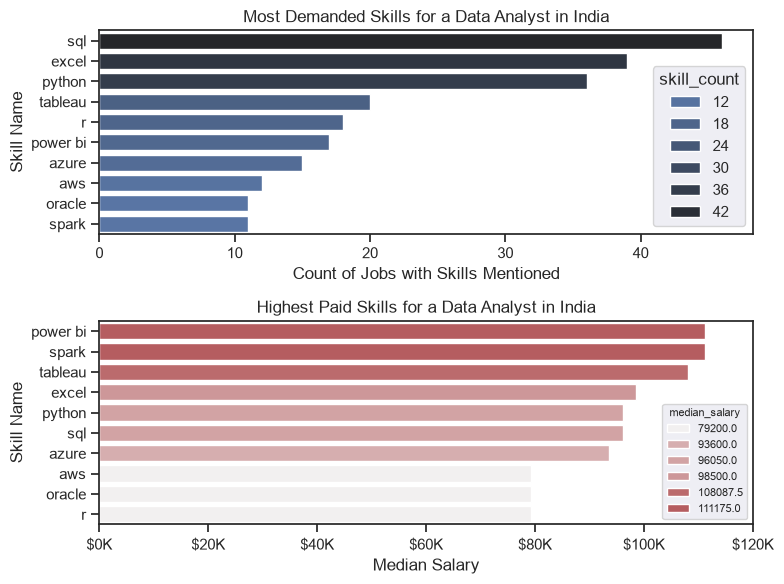

In [51]:
fig, ax = plt.subplots(2, 1, figsize=(8, 6))

sns.set_theme(style='darkgrid')
sns.barplot(data = df_demand, x = 'skill_count', y = 'job_skills', ax=ax[0], hue='skill_count', palette = 'dark:b_r')
#df_demand[::-1].plot(kind='barh', ax=ax[0])
ax[0].set_title('Most Demanded Skills for a Data Analyst in India')
ax[0].set_ylabel('Skill Name')
ax[0].set_xlabel('Count of Jobs with Skills Mentioned')

sns.barplot(data = df_money, x = 'median_salary', y = 'job_skills', ax=ax[1], hue='median_salary', palette = 'light:r')
#df_money[::-1].plot(kind='barh', ax=ax[1])
ax[1].set_title('Highest Paid Skills for a Data Analyst in India')
ax[1].set_xlim(0, 120000)
ax[1].set_ylabel('Skill Name')
ax[1].set_xlabel('Median Salary')
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
sns.move_legend(
    ax[1],
    "lower right",
    fontsize=8,       # Smaller text size
    title_fontsize=8, # Smaller title size
    markerscale=0.7   # Smaller color swatches
)

plt.tight_layout()

In [27]:
df_demand

,job_skills,skill_count,median_salary
0,sql,46,96050.0
1,excel,39,98500.0
2,python,36,96050.0
3,tableau,20,108087.5
4,r,18,79200.0
5,power bi,17,111175.0
6,azure,15,93600.0
7,aws,12,79200.0
8,oracle,11,79200.0
9,spark,11,111175.0


In [32]:
df_money

,skill_count,median_salary
job_skills,,
power bi,17,111175.0
spark,11,111175.0
tableau,20,108087.5
excel,39,98500.0
python,36,96050.0
sql,46,96050.0
azure,15,93600.0
aws,12,79200.0
oracle,11,79200.0
